# Segment the cloth part of pool table

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
DATA_DIR = Path("./../data")
IMAGE_PATH = DATA_DIR / "development_set/4a_png.rf.a6bb5c5706fd8628eb53d34a122cf441.jpg"

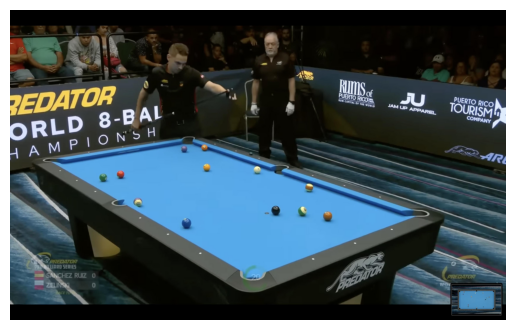

In [3]:
image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(image)
plt.axis('off')
plt.show()

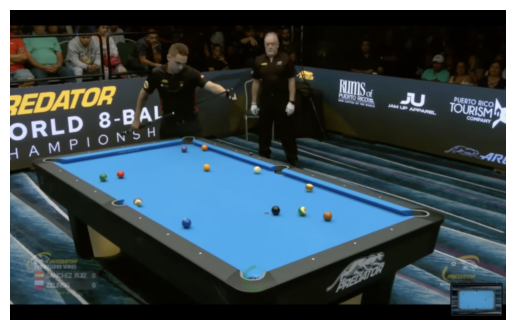

In [4]:
image = cv2.GaussianBlur(image, (15, 15), 0)
plt.imshow(image)
plt.axis('off')
plt.show()

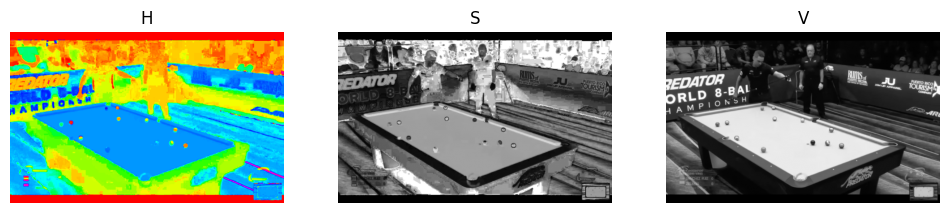

In [5]:
hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

# Plot all three channels of the HSV image
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes[0].imshow(hsv_image[:, :, 0], cmap='hsv')
axes[0].set_title('H')
axes[0].axis('off')
axes[1].imshow(hsv_image[:, :, 1], cmap='gray')
axes[1].set_title('S')
axes[1].axis('off')
axes[2].imshow(hsv_image[:, :, 2], cmap='gray')
axes[2].set_title('V')
axes[2].axis('off')
plt.show()

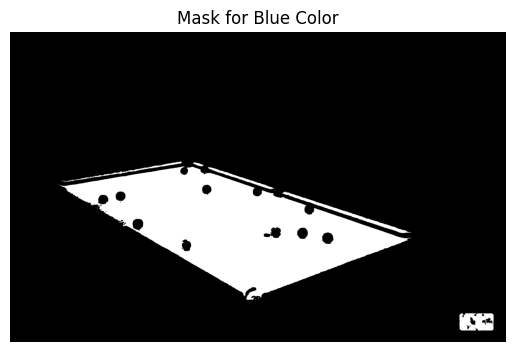

In [6]:
lower_blue = np.array([200/2, 60 / 100 * 255, 60 / 100 * 255])
upper_blue = np.array([210/2, 90 / 100 * 255, 100 / 100 * 255])

mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title('Mask for Blue Color')
plt.show()

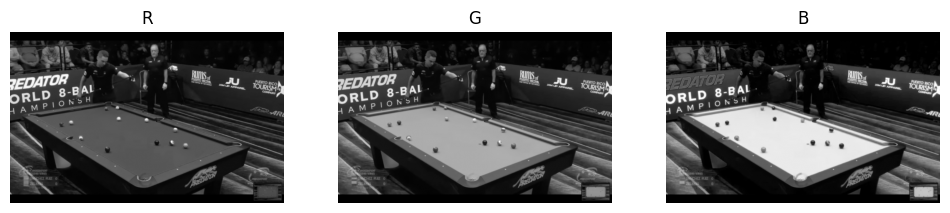

In [7]:
# make 3 plots for each channel of RGD image
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes[0].imshow(image[:, :, 0], cmap='gray')
axes[0].set_title('R')
axes[0].axis('off')
axes[1].imshow(image[:, :, 1], cmap='gray')
axes[1].set_title('G')
axes[1].axis('off')
axes[2].imshow(image[:, :, 2], cmap='gray')
axes[2].set_title('B')
axes[2].axis('off')
plt.show()

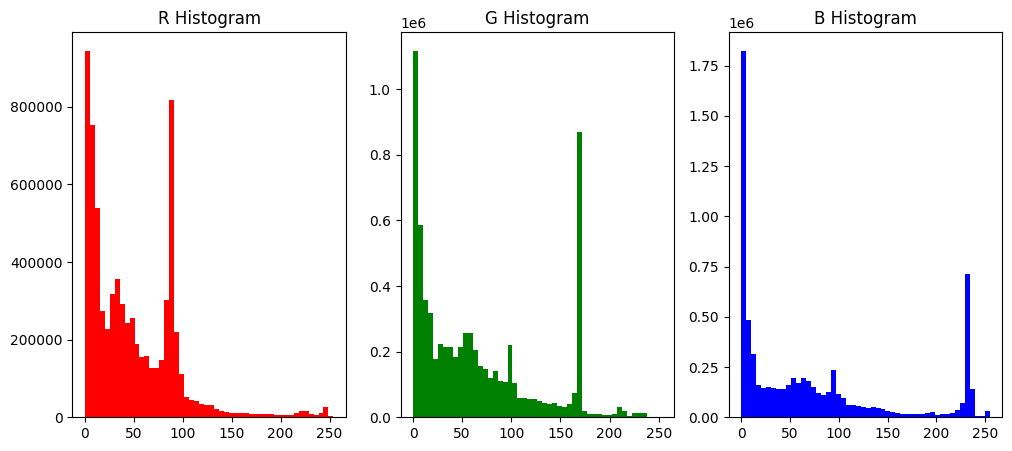

In [8]:
# make histogram for each channel of the RGB image
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes[0].hist(image[:, :, 0].ravel(), bins=50, color='red')
axes[0].set_title('R Histogram')
axes[1].hist(image[:, :, 1].ravel(), bins=50, color='green')
axes[1].set_title('G Histogram')
axes[2].hist(image[:, :, 2].ravel(), bins=50, color='blue')
axes[2].set_title('B Histogram')
plt.show()

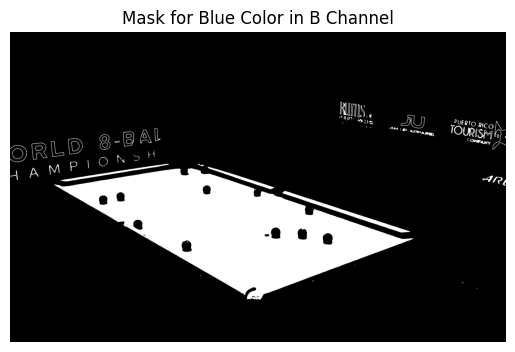

In [9]:
lower_blue = 200
upper_blue = 240

mask_table = cv2.inRange(image[:, :, 2], lower_blue, upper_blue)

plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title('Mask for Blue Color in B Channel')
plt.show()